# Shopping Mall Paid Search — Data Exploration

## Executive Summary

The dataset covers 190 monthly ad-group records from July to November 2021. It has no missing values or duplicate rows. One source field does need care: the published conversion rate does not match `conversions / clicks` in 160 rows. For that reason, this analysis recalculates every KPI from the underlying counts instead of relying on the supplied ratios.

The main comparison is match type: One-to-one, Exact and Phrase. These labels come directly from the ad-group names, so the groups were defined without looking at which one performed best. Device is used as a secondary view.

This is a historical, observational analysis. It can show where results moved together, but it cannot prove that match type or device caused the differences.

## Business Question and Approach

The business question is straightforward: how did paid-search efficiency and profitability vary by match type, and which areas should the marketing team maintain, optimise or reduce?

**Source.** [Shopping Mall Paid Search Campaign Dataset](https://www.kaggle.com/datasets/marceaxl82/shopping-mall-paid-search-campaign-dataset), published by Marcello D. (`marceaxl82`) under CC0. The publisher describes a real, anonymized US shopping-mall paid-search campaign covering July–November 2021. The underlying company's identity and provenance cannot be independently verified from the public file.

### Working assumptions

- A row is one `ad_group × month` observation; this is validated as a unique composite key.
- `Revenue` is used as the dataset's revenue measure. `Sale Amount` is retained but not treated as revenue because the source does not provide a sufficiently precise financial definition.
- Published ratio columns are audit fields only. Recalculated ratios are authoritative.
- Exact duplicate rows are reported but not removed automatically.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "marketing_analysis.py").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the repository root or notebooks directory.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from marketing_analysis import prepare_data, quality_checks, aggregate_performance, MONTH_ORDER, MATCH_ORDER

DATA_PATH = PROJECT_ROOT / "data" / "shopping_mall_paid_search.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(42)
pd.set_option("display.max_columns", 50)
print("Project root located successfully.")
print("Data source:", DATA_PATH.relative_to(PROJECT_ROOT))

Project root located successfully.
Data source: data/shopping_mall_paid_search.csv


## Data

### Data dictionary

The first table separates fields supplied by the publisher from fields calculated in this project. Currency values are reported exactly as they appear in the dataset. The source does not explain tax treatment, attribution windows, product margin, or whether revenue is gross or net.

In [2]:
raw = pd.read_csv(DATA_PATH)
df = prepare_data(DATA_PATH)
PREPARED_DATA_PATH = PROJECT_ROOT / "data" / "marketing_data.csv"
df.to_csv(PREPARED_DATA_PATH, index=False)
print("Prepared dataset saved to:", PREPARED_DATA_PATH.relative_to(PROJECT_ROOT))

dictionary = pd.DataFrame([
    ("ad_group", "Source", "Anonymized structural ad-group name"),
    ("month", "Source", "Monthly reporting period, July–November 2021"),
    ("impressions", "Source", "Ads served; awareness volume"),
    ("clicks", "Source", "Ad clicks; traffic volume"),
    ("conversions", "Source", "Attributed conversions reported by the publisher"),
    ("cost", "Source", "Paid-search spend"),
    ("revenue", "Source", "Revenue measure reported by the publisher"),
    ("sale_amount", "Source", "Separate sales-value field; definition not independently verified"),
    ("source_ctr / source_conversion_rate / source_cpc / source_p_and_l", "Source", "Published metrics retained only for reconciliation"),
    ("device", "Engineered", "Desktop or Mobile parsed from ad_group"),
    ("match_type", "Engineered", "One-to-one, Exact, or Phrase parsed from ad_group"),
    ("intent_family", "Engineered", "Term family parsed structurally from ad_group"),
    ("ctr", "Engineered", "clicks / impressions"),
    ("conversion_rate", "Engineered", "conversions / clicks"),
    ("cpc", "Engineered", "cost / clicks"),
    ("cpa", "Engineered", "cost / conversions"),
    ("revenue_per_conversion", "Engineered", "revenue / conversions"),
    ("profit", "Engineered", "revenue - cost"),
    ("profit_per_conversion", "Engineered", "profit / conversions"),
    ("roas", "Engineered", "revenue / cost"),
    ("roi", "Engineered", "profit / cost"),
    ("profit_margin", "Engineered", "profit / revenue"),
], columns=["field", "origin", "definition"])
dictionary

Prepared dataset saved to: data/marketing_data.csv


,field,origin,definition
0,ad_group,Source,Anonymized structural ad-group name
1,month,Source,"Monthly reporting period, July–November 2021"
2,impressions,Source,Ads served; awareness volume
3,clicks,Source,Ad clicks; traffic volume
4,conversions,Source,Attributed conversions reported by the publisher
5,cost,Source,Paid-search spend
6,revenue,Source,Revenue measure reported by the publisher
7,sale_amount,Source,Separate sales-value field; definition not ind...
8,source_ctr / source_conversion_rate / source_c...,Source,Published metrics retained only for reconcilia...
9,device,Engineered,Desktop or Mobile parsed from ad_group


### Shape, types, grain, and coverage

In [3]:
print(f"Raw shape: {raw.shape}")
print(f"Prepared shape: {df.shape}")
print("Unit of observation: one ad_group × month row")
print("Months:", [str(x) for x in df["month"].dropna().unique()])
print("Unique ad groups:", df["ad_group"].nunique())
print("Rows per month:")
display(df.groupby("month", observed=True).size().rename("rows").to_frame())
display(raw.dtypes.rename("dtype").to_frame())

Raw shape: (190, 12)
Prepared shape: (190, 25)
Unit of observation: one ad_group × month row
Months: ['July', 'August', 'September', 'October', 'November']
Unique ad groups: 40
Rows per month:


,rows
month,
July,38
August,38
September,38
October,37
November,39


,dtype
Ad Group,str
Month,str
Impressions,int64
Clicks,int64
CTR,float64
Conversions,int64
Conv Rate,float64
Cost,int64
CPC,float64
Revenue,int64


### Data checks and source-metric reconciliation

When a denominator is zero, the result is left undefined as `NaN`; it is never replaced with zero. A negative profit is a possible business result, so it is not treated as a data error. Missing ad-group/month combinations are reported rather than filled with invented values.

In [4]:
checks = quality_checks(raw, df)
display(checks)
print("Failed checks:")
display(checks.loc[~checks["passed"]])
print("Missing ad_group × month combinations:", df["ad_group"].nunique() * df["month"].nunique() - len(df))
checks.to_csv(OUTPUT_DIR / "data_quality_checks.csv", index=False)

,check,observed,expected,passed
0,rows,190,190,True
1,columns_source,12,12,True
2,missing_cells,0,0,True
3,exact_duplicate_rows,0,0,True
4,duplicate_ad_group_month_keys,0,0,True
5,clicks_gt_impressions,0,0,True
6,conversions_gt_clicks,0,0,True
7,negative_input_values,0,0,True
8,zero_impressions,0,0,True
9,zero_clicks,0,0,True


Failed checks:


,check,observed,expected,passed
16,source_conversion_rate_diff_gt_0.0051,160,0,False
17,source_cpc_diff_gt_0.011,16,0,False


Missing ad_group × month combinations: 10


In [5]:
metric_reconciliation = pd.DataFrame({
    "metric": ["CTR", "Conversion rate", "CPC", "P&L"],
    "source_field": ["source_ctr", "source_conversion_rate", "source_cpc", "source_p_and_l"],
    "recalculation": ["clicks / impressions", "conversions / clicks", "cost / clicks", "revenue - cost"],
    "max_absolute_difference": [
        (df["source_ctr"] - df["ctr"]).abs().max(),
        (df["source_conversion_rate"] - df["conversion_rate"]).abs().max(),
        (df["source_cpc"] - df["cpc"]).abs().max(),
        (df["source_p_and_l"] - df["profit"]).abs().max(),
    ],
    "rows_outside_rounding_tolerance": [
        ((df["source_ctr"] - df["ctr"]).abs() > 0.0051).sum(),
        ((df["source_conversion_rate"] - df["conversion_rate"]).abs() > 0.0051).sum(),
        ((df["source_cpc"] - df["cpc"]).abs() > 0.011).sum(),
        ((df["source_p_and_l"] - df["profit"]).abs() > 0.51).sum(),
    ],
})
metric_reconciliation

,metric,source_field,recalculation,max_absolute_difference,rows_outside_rounding_tolerance
0,CTR,source_ctr,clicks / impressions,0.005000,0
1,Conversion rate,source_conversion_rate,conversions / clicks,0.250000,160
2,CPC,source_cpc,cost / clicks,0.286667,16
3,P&L,source_p_and_l,revenue - cost,0.499000,0


### What the checks mean for the analysis

CTR and P&L reconcile within normal rounding tolerance. The supplied conversion rate does not: 160 of 190 rows differ from the value obtained by dividing conversions by clicks. CPC also has 16 small discrepancies, mainly where rounded source values magnify the difference.

For the marketing team, the relevant point is that the raw counts are internally usable, while some pre-calculated ratios are not. All comparisons that follow use recalculated KPIs. No rows were deleted to make the results look cleaner.

## What the Data Shows

### Structural comparison groups

The second segment of `Ad Group` provides the grouping rule: `1:1 → One-to-one`, `Exact → Exact`, and `Phrase → Phrase`. This gives three groups with 50, 72 and 68 monthly observations respectively. Device (`Desk → Desktop`, `Mob → Mobile`) provides a second view. Intent family is available for exploration, but it is not used to select winners or losers.

In [6]:
group_structure = (
    df.groupby(["match_type", "device"], observed=True)
      .agg(observations=("ad_group", "size"), ad_groups=("ad_group", "nunique"), months=("month", "nunique"))
      .reset_index()
)
display(group_structure)
display(df.groupby("intent_family", observed=True).agg(observations=("ad_group", "size"), ad_groups=("ad_group", "nunique")).sort_values("observations", ascending=False))

,match_type,device,observations,ad_groups,months
0,Exact,Desktop,36,8,5
1,Exact,Mobile,36,8,5
2,One-to-one,Desktop,25,5,5
3,One-to-one,Mobile,25,5,5
4,Phrase,Desktop,33,7,5
5,Phrase,Mobile,35,7,5


,observations,ad_groups
intent_family,,
Coupon,40,8
Promo,40,8
Discount,30,6
Free Shipping,20,4
Offer,20,4
Sale,20,4
Competitor,18,4
Black Friday / Cyber Monday,2,2


### Marketing funnel and unit economics

| Stage | KPI | Business question | Decision supported |
|---|---|---|---|
| Awareness | Impressions | How much eligible search demand did ads reach? | Coverage and reach priorities |
| Traffic / consideration | Clicks, CTR, CPC | Did ads attract traffic, and at what media cost? | Creative/query relevance and bid control |
| Conversion | Conversions, conversion rate, CPA | Did traffic convert efficiently? | Landing-page, targeting, and acquisition decisions |
| Revenue | Revenue, revenue per conversion | How much reported revenue did conversions generate? | Value quality and mix |
| Profitability | Profit, profit margin, ROAS, ROI | Did reported revenue cover media cost? | Budget guardrails and optimisation |

LTV, product gross margin, incrementality, and external benchmarks are absent. Consequently, a true break-even CPA or ROAS cannot be established; ROAS = 1 is only media-cost break-even under the dataset's reported revenue definition, not full business break-even.

In [7]:
match_summary = aggregate_performance(df, "match_type")
device_summary = aggregate_performance(df, "device")
monthly_summary = aggregate_performance(df, "month")

display(match_summary.round(4))
display(device_summary.round(4))
match_summary.to_csv(OUTPUT_DIR / "group_performance_summary.csv", index=False)
device_summary.to_csv(OUTPUT_DIR / "device_performance_summary.csv", index=False)
monthly_summary.to_csv(OUTPUT_DIR / "monthly_performance.csv", index=False)

,match_type,observations,ad_groups,impressions,clicks,conversions,cost,revenue,sale_amount,ctr,conversion_rate,cpc,cpa,revenue_per_conversion,profit,profit_per_conversion,roas,roi,profit_margin
0,One-to-one,50,10,1755536,689174,72388,462655,413904,8820667.73,0.3926,0.1050,0.6713,6.3913,5.7179,-48751,-0.6735,0.8946,-0.1054,-0.1178
1,Exact,72,16,523594,149042,15038,105319,93298,2044743.76,0.2847,0.1009,0.7066,7.0035,6.2041,-12021,-0.7994,0.8859,-0.1141,-0.1288
2,Phrase,68,14,395569,86287,8570,67398,54758,1183662.82,0.2181,0.0993,0.7811,7.8644,6.3895,-12640,-1.4749,0.8125,-0.1875,-0.2308


,device,observations,ad_groups,impressions,clicks,conversions,cost,revenue,sale_amount,ctr,conversion_rate,cpc,cpa,revenue_per_conversion,profit,profit_per_conversion,roas,roi,profit_margin
0,Desktop,94,20,757893,234939,42190,286841,258831,5575436.43,0.3100,0.1796,1.2209,6.7988,6.1349,-28010,-0.6639,0.9024,-0.0976,-0.1082
1,Mobile,96,20,1916806,689564,53806,348531,303129,6473637.88,0.3597,0.0780,0.5054,6.4775,5.6337,-45402,-0.8438,0.8697,-0.1303,-0.1498


### Business interpretation of the KPI table

One-to-one carried most of the volume and had the lowest CPA at $6.39. Exact followed at $7.00, while Phrase cost $7.86 per conversion. The profitability picture is less encouraging: ROAS was below 1 and ROI was negative for all three groups. In practical terms, the reported revenue did not cover media cost in any match type.

Desktop showed a higher observed conversion rate than Mobile (17.96% versus 7.80%), while Mobile delivered far more clicks and a slightly lower CPA. This suggests a meaningful device mix difference, but it does not prove that the device itself caused the gap. Query mix, bids, landing pages and attribution may also explain it.

### Charts for the marketing review

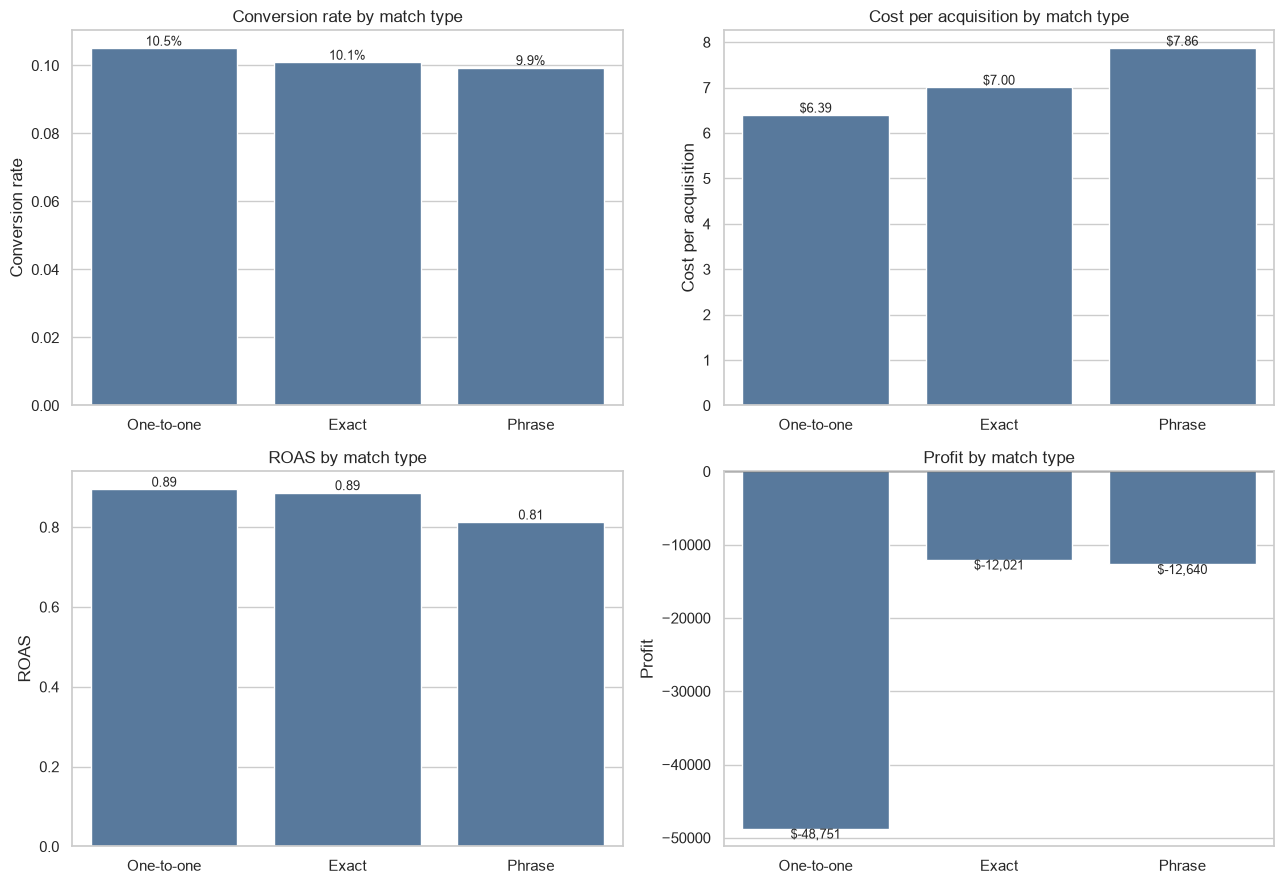

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_specs = [
    ("conversion_rate", "Conversion rate", ".1%", ""),
    ("cpa", "Cost per acquisition", ",.2f", "$"),
    ("roas", "ROAS", ".2f", ""),
    ("profit", "Profit", ",.0f", "$"),
]
for ax, (metric, title, fmt, prefix) in zip(axes.flat, plot_specs):
    sns.barplot(data=match_summary, x="match_type", y=metric, ax=ax, color="#4C78A8")
    ax.set_title(f"{title} by match type")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    if metric == "profit":
        ax.axhline(0, color="black", lw=1)
    for patch, value in zip(ax.patches, match_summary[metric]):
        label = prefix + format(value, fmt)
        ax.annotate(label, (patch.get_x() + patch.get_width()/2, patch.get_height()),
                    ha="center", va="bottom" if value >= 0 else "top", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "group_kpis.png", dpi=180, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "group_metrics_overview.png", dpi=180, bbox_inches="tight")
plt.show()

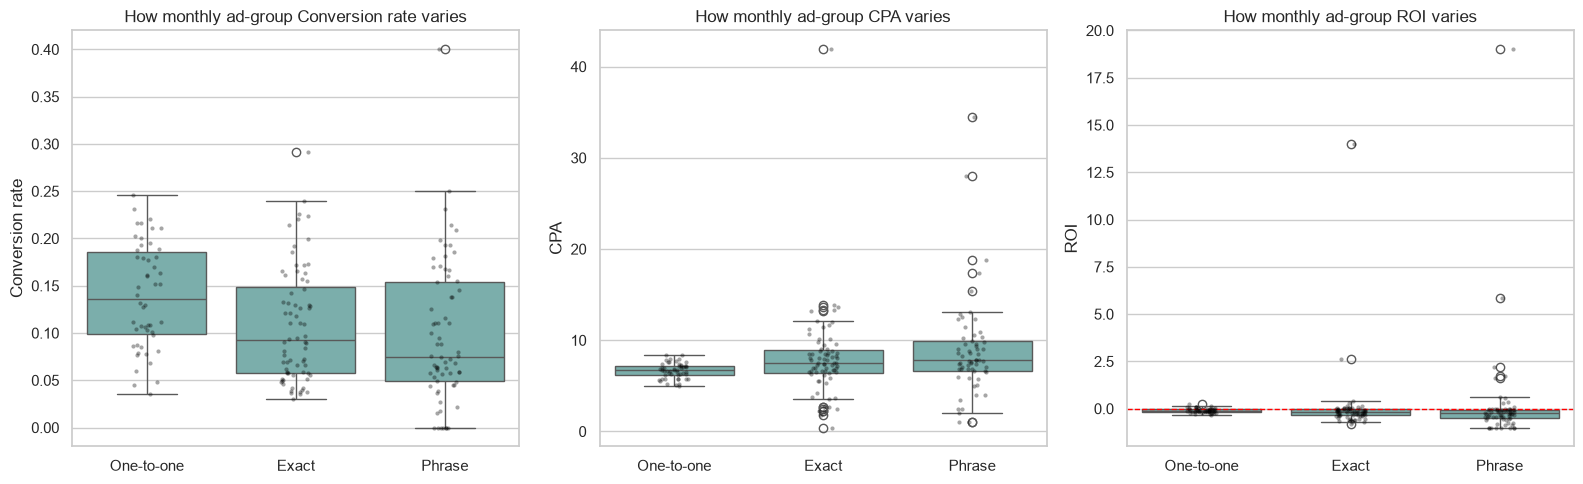

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric, label in zip(axes, ["conversion_rate", "cpa", "roi"], ["Conversion rate", "CPA", "ROI"]):
    sns.boxplot(data=df, x="match_type", y=metric, order=MATCH_ORDER, ax=ax, color="#72B7B2")
    sns.stripplot(data=df, x="match_type", y=metric, order=MATCH_ORDER, ax=ax,
                  color="black", alpha=.35, size=3)
    ax.set_title(f"How monthly ad-group {label} varies")
    ax.set_xlabel("")
    ax.set_ylabel(label)
    if metric == "roi": ax.axhline(0, color="red", ls="--", lw=1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "metric_distributions.png", dpi=180, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "group_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

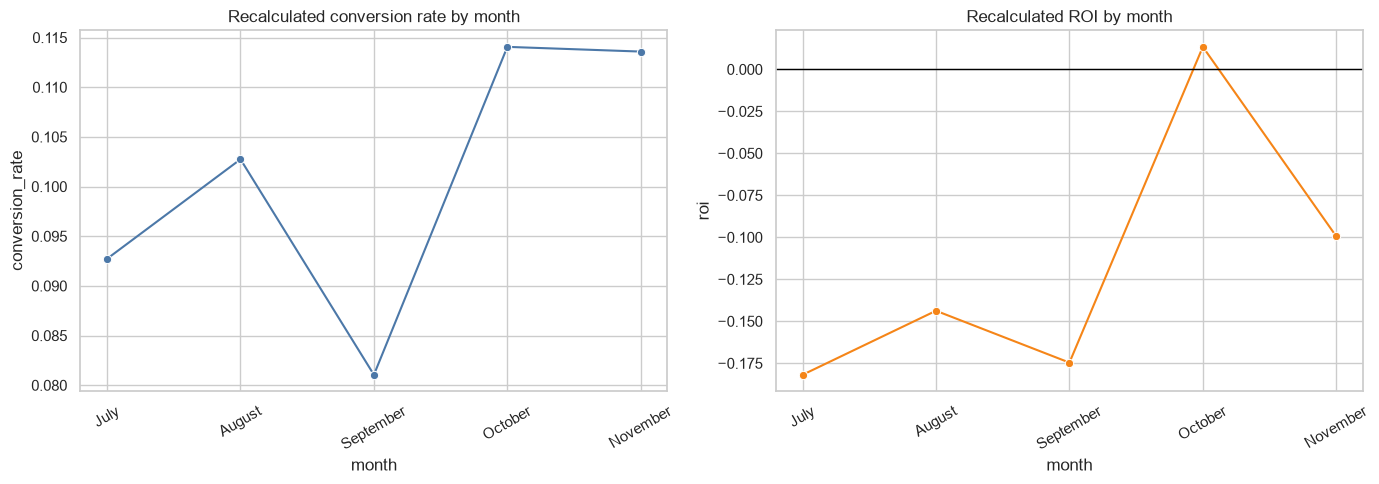

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=monthly_summary, x="month", y="conversion_rate", marker="o", ax=axes[0], color="#4C78A8")
sns.lineplot(data=monthly_summary, x="month", y="roi", marker="o", ax=axes[1], color="#F58518")
axes[0].set_title("Recalculated conversion rate by month")
axes[1].set_title("Recalculated ROI by month")
axes[1].axhline(0, color="black", lw=1)
for ax in axes: ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "monthly_trends.png", dpi=180, bbox_inches="tight")
plt.show()

## Key Findings

One-to-one is the strongest relative performer: it supplied most conversions and had the best CPA and ROAS of the three groups. It is not a profitable winner, however. Its ROI was still −10.5%.

Phrase had the weakest CPA, ROAS and ROI. The data supports reducing exposure and reviewing its search terms, but not assuming that every Phrase keyword should be paused. Performance may vary within the group.

Desktop converted at a higher observed rate, while Mobile supplied most clicks and had a slightly lower CPA. The sensible next step is a device-level diagnostic, not a claim that Desktop traffic is inherently better.

Most importantly, all three match types lost money under `profit = revenue - cost`. The data is strong enough to identify areas for optimisation, but not to justify broad scaling or a causal claim.

### Limitations

The dataset is monthly and aggregated, covers only five months, and is missing ten possible ad-group/month combinations. It has no user-level assignment, keyword-auction detail, attribution window, margin, seasonality controls or experimental randomisation. The same ad groups appear across months, so those rows are related rather than fully independent. The public claim that the data comes from a real company also cannot be independently verified. These limits keep the findings descriptive.